In [10]:
%matplotlib inline
from amuse.lab import *
from amuse.ic.fractalcluster import new_fractal_cluster_model
import numpy as np
from matplotlib import pyplot as plt

In [8]:
from amuse.ic.kroupa import new_kroupa_mass_distribution

n_stars = 1000
mass_min = 0.01 | units.MSun
mass_max = 100 | units.MSun

masses_kroupa = new_kroupa_mass_distribution(
    n_stars, 
    mass_min=mass_min, 
    mass_max=mass_max
    )

In [ ]:

# we will look over this & refine it later
fractal_dimension = 2.0
length_scale = 1.0 | units.parsec
mass_scale = masses_kroupa.sum()

converter = nbody_system.nbody_to_si(mass_scale,  length_scale)

particles_fractal = new_fractal_cluster_model(
    n_stars,
    fractal_dimension=2.0,
    convert_nbody=converter
)


print(particles_fractal[:5])

particles_fractal.mass = masses_kroupa
particles_fractal.radius = 0.5 | units.au

particles_fractal.move_to_center()

print(particles_fractal[:5])

                 key         mass       radius           vx           vy           vz            x            y            z
                   -           kg            m    m * s**-1    m * s**-1    m * s**-1            m            m            m
====================  ===========  ===========  ===========  ===========  ===========  ===========  ===========  ===========
 8193855072930670985    1.279e+30    0.000e+00   -2.223e+02    2.030e+01    2.663e+02   -2.766e+16    2.436e+16   -1.039e+15
 4088992021941200066    1.279e+30    0.000e+00   -2.595e+02   -2.219e+00    3.407e+02    2.587e+16   -1.486e+16    2.107e+16
15519783323809716853    1.279e+30    0.000e+00   -1.487e+02    8.469e+01    1.293e+02   -1.113e+16   -1.769e+16    2.461e+16
 5541153676669736185    1.279e+30    0.000e+00    1.790e+01   -5.610e+02   -1.389e+02    4.579e+15   -2.767e+15   -7.634e+15
 3108255614214412164    1.279e+30    0.000e+00   -2.021e+02    2.254e+02    5.153e+01   -1.456e+16    2.673e+16   -2.434e+16


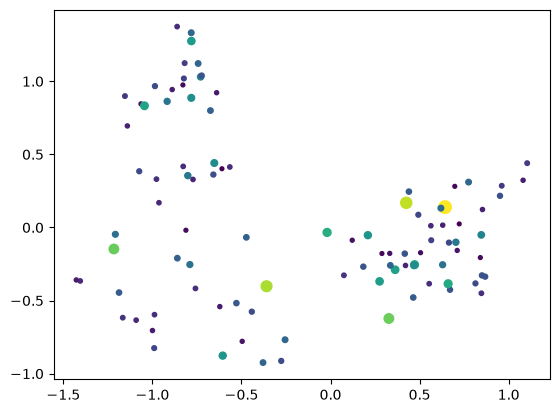

In [11]:
plt.scatter(
    particles_fractal.x.value_in(units.pc),
    particles_fractal.y.value_in(units.pc),
    c=np.log10(particles_fractal.mass.value_in(units.MSun)),
    s=25. * np.sqrt(particles_fractal.mass.value_in(units.MSun))
)
plt.show()